<a href="https://colab.research.google.com/github/dhianab12-commits/machinelearningKNN/blob/main/Prediksi%20KNN%20tanpa%20Pola%20Asuh%20Untitled16.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

print("--- 1. INPUT DATA ---")
# Memuat dataset (sesuaikan nama file secara verbatim)
nama_file = "/content/Data_Balita_0_2_Tahun.csv"

try:
    df_balita = pd.read_csv(nama_file, sep=None, engine='python')

    # Membersihkan spasi tersembunyi pada header kolom
    df_balita.columns = df_balita.columns.str.strip()

    print("Data berhasil dimuat!")
    print(f"Total baris: {df_balita.shape[0]}, Total kolom: {df_balita.shape[1]}")
    display(df_balita.head(5))
except Exception as e:
    print(f"Error memuat data: {e}")

--- 1. INPUT DATA ---
Data berhasil dimuat!
Total baris: 567, Total kolom: 12


,Nama,Jenis Kelamin,Usia Saat Ukur,Berat,Tinggi,BB/U,ZS BB/U,TB/U,ZS TB/U,BB/TB,ZS BB/TB,Label_Stunting
0,RAMIRO ARGANTARA,Laki-Laki,21,11.1,74.2,Normal,-0.46,Pendek,-2.45,Gizi Baik,0.20,Berisiko Stunting
1,ALICIA G. DOS REIA,Perempuan,21,8.8,79.4,Normal,-1.82,Normal,-1.51,Gizi Baik,-1.43,Normal
2,DRAGON RAFAEL,Laki-Laki,19,10.9,73.7,Normal,-0.24,Pendek,-2.87,Gizi Baik,0.10,Berisiko Stunting
3,YOSEP R. C. BENYAMIN,Laki-Laki,19,9.6,68.0,Normal,-1.36,Sangat Pendek,-3.88,Gizi Baik,-1.03,Stunting
4,ANJELINA SARMENTO,Perempuan,17,7.7,75.0,Kurang,-2.34,Normal,-1.86,Gizi Baik,-1.98,Normal


In [3]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

print("\n--- 2. PRA-PEMROSESAN DATA ---")

# A. Pembersihan Data (Cleaning & Imputasi)
df_bersih = df_balita.copy()
df_bersih.drop_duplicates(inplace=True)

# B. Transformasi / Encoding (Laki-laki = 1, Perempuan = 0)
if 'Jenis Kelamin' in df_bersih.columns:
    pemetaan_jk = {'Laki-Laki': 1, 'Laki-laki': 1, 'laki-laki': 1, 'Perempuan': 0, 'perempuan': 0}
    df_bersih['Jenis_Kelamin_Encoded'] = df_bersih['Jenis Kelamin'].astype(str).str.strip().map(pemetaan_jk)
    df_bersih['Jenis_Kelamin_Encoded'].fillna(df_bersih['Jenis_Kelamin_Encoded'].mode()[0], inplace=True)

# Menentukan fitur input (Variabel Independen/X)
fitur_x = ['Usia Saat Ukur', 'Berat', 'Tinggi', 'Jenis_Kelamin_Encoded']
X_mentah = df_bersih[fitur_x].copy()

# Memastikan tipe data fitur menjadi numerik dan membuang error/teks tersembunyi
for col in fitur_x:
    X_mentah[col] = X_mentah[col].astype(str).str.replace(',', '.', regex=False)
    X_mentah[col] = X_mentah[col].replace(['#VALUE!', 'nan', 'NaN', 'None', ''], np.nan)
    X_mentah[col] = X_mentah[col].str.replace(r'[^\d.]', '', regex=True)
    X_mentah[col] = pd.to_numeric(X_mentah[col], errors='coerce')

# Mengisi nilai yang kosong (missing values) dengan nilai rata-rata (mean)
X_mentah.fillna(X_mentah.mean(), inplace=True)

# C. Normalisasi Data (Min-Max Scaler)
scaler = MinMaxScaler()
X_normalized = scaler.fit_transform(X_mentah)
X = pd.DataFrame(X_normalized, columns=fitur_x)

print("Pra-pemrosesan selesai. Contoh hasil normalisasi data (X):")
display(X.head())


--- 2. PRA-PEMROSESAN DATA ---
Pra-pemrosesan selesai. Contoh hasil normalisasi data (X):


/tmp/ipykernel_2013/649189677.py:14: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_bersih['Jenis_Kelamin_Encoded'].fillna(df_bersih['Jenis_Kelamin_Encoded'].mode()[0], inplace=True)


,Usia Saat Ukur,Berat,Tinggi,Jenis_Kelamin_Encoded
0,0.875000,0.723214,0.744292,1.0
1,0.875000,0.517857,0.863014,0.0
2,0.791667,0.705357,0.732877,1.0
3,0.791667,0.589286,0.602740,1.0
4,0.708333,0.419643,0.762557,0.0


In [7]:
from IPython.display import display

print("\n--- 3. PELABELAN DATA (TARGET) ---")

# Memastikan Z-Score berformat desimal yang benar
df_bersih['ZS TB/U'] = df_bersih['ZS TB/U'].astype(str).str.replace(',', '.', regex=False)
df_bersih['ZS TB/U'] = pd.to_numeric(df_bersih['ZS TB/U'], errors='coerce')
df_bersih['ZS TB/U'].fillna(df_bersih['ZS TB/U'].median(), inplace=True)

# Fungsi Pelabelan Permenkes RI
def label_stunting(z_score):
    if z_score >= -2.0:
        return 'Normal'
    elif -3.0 <= z_score < -2.0:
        return 'Risiko Stunting'
    else:
        return 'Stunting'

# Menerapkan pelabelan
y = df_bersih['ZS TB/U'].apply(label_stunting)

# Menyisipkan hasil pelabelan ke dalam dataframe sebagai kolom baru
df_bersih['Label_Stunting_KNN'] = y

print("Distribusi Kelas Status Gizi:")
print(y.value_counts())

# Memunculkan 10 baris pertama dalam bentuk tabel interaktif
print("\n[ Cuplikan Tabel Hasil Pelabelan ]")
display(df_bersih.head(5))


--- 3. PELABELAN DATA (TARGET) ---
Distribusi Kelas Status Gizi:
ZS TB/U
Risiko Stunting    189
Normal             189
Stunting           189
Name: count, dtype: int64

[ Cuplikan Tabel Hasil Pelabelan ]


/tmp/ipykernel_2013/1614632927.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_bersih['ZS TB/U'].fillna(df_bersih['ZS TB/U'].median(), inplace=True)


,Nama,Jenis Kelamin,Usia Saat Ukur,Berat,Tinggi,BB/U,ZS BB/U,TB/U,ZS TB/U,BB/TB,ZS BB/TB,Label_Stunting,Jenis_Kelamin_Encoded,Label_Stunting_KNN
0,RAMIRO ARGANTARA,Laki-Laki,21,11.1,74.2,Normal,-0.46,Pendek,-2.45,Gizi Baik,0.20,Berisiko Stunting,1,Risiko Stunting
1,ALICIA G. DOS REIA,Perempuan,21,8.8,79.4,Normal,-1.82,Normal,-1.51,Gizi Baik,-1.43,Normal,0,Normal
2,DRAGON RAFAEL,Laki-Laki,19,10.9,73.7,Normal,-0.24,Pendek,-2.87,Gizi Baik,0.10,Berisiko Stunting,1,Risiko Stunting
3,YOSEP R. C. BENYAMIN,Laki-Laki,19,9.6,68.0,Normal,-1.36,Sangat Pendek,-3.88,Gizi Baik,-1.03,Stunting,1,Stunting
4,ANJELINA SARMENTO,Perempuan,17,7.7,75.0,Kurang,-2.34,Normal,-1.86,Gizi Baik,-1.98,Normal,0,Normal


In [9]:
from sklearn.model_selection import train_test_split
from IPython.display import display
import pandas as pd

print("\n--- 4. PEMBAGIAN DATASET ---")

# Memastikan indeks pada data asli dan data yang sudah dinormalisasi sejajar
df_bersih.reset_index(drop=True, inplace=True)
X.reset_index(drop=True, inplace=True)
y.reset_index(drop=True, inplace=True)

# Membagi dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Total Data Latih (Training) : {X_train.shape[0]} baris (80%)")
print(f"Total Data Uji (Testing)    : {X_test.shape[0]} baris (20%)")

# =========================================================
# MENAMPILKAN HASIL PEMBAGIAN BERDASARKAN NAMA BALITA
# =========================================================

# 1. Menyiapkan Tabel Data Latih (Mengambil Nama berdasarkan Indeks X_train)
tabel_train = X_train.copy()
tabel_train.insert(0, 'Nama Balita', df_bersih.loc[X_train.index, 'Nama'])
tabel_train['Label Status Gizi'] = y_train

# 2. Menyiapkan Tabel Data Uji (Mengambil Nama berdasarkan Indeks X_test)
tabel_test = X_test.copy()
tabel_test.insert(0, 'Nama Balita', df_bersih.loc[X_test.index, 'Nama'])
tabel_test['Label Status Gizi'] = y_test

# 3. Menampilkan Cuplikan Tabel Latih
print("\n[ Tabel Data Latih / Training (80%) - Menampilkan 5 Baris Pertama ]")
display(tabel_train.head())

# 4. Menampilkan Cuplikan Tabel Uji
print("\n[ Tabel Data Uji / Testing (20%) - Menampilkan 5 Baris Pertama ]")
display(tabel_test.head())


--- 4. PEMBAGIAN DATASET ---
Total Data Latih (Training) : 453 baris (80%)
Total Data Uji (Testing)    : 114 baris (20%)

[ Tabel Data Latih / Training (80%) - Menampilkan 5 Baris Pertama ]


,Nama Balita,Usia Saat Ukur,Berat,Tinggi,Jenis_Kelamin_Encoded,Label Status Gizi
117,ASLAN JUNIOR,0.166667,0.285714,0.442922,1.0,Normal
211,MARTINUS JUAN SOARES,0.833333,0.598214,0.584475,1.0,Stunting
0,RAMIRO ARGANTARA,0.875000,0.723214,0.744292,1.0,Risiko Stunting
328,BENYAMIN ASUAT,0.000000,0.071429,0.000000,1.0,Stunting
11,BY. NY NI\'MATUL HOERIYAH,0.500000,0.383929,0.616438,0.0,Risiko Stunting



[ Tabel Data Uji / Testing (20%) - Menampilkan 5 Baris Pertama ]


,Nama Balita,Usia Saat Ukur,Berat,Tinggi,Jenis_Kelamin_Encoded,Label Status Gizi
540,ABDIEL BRIANDO DEJESUS,0.833333,0.625000,0.910959,1.0,Normal
525,WAHID AHMAD FIRDAUS,0.208333,0.375000,0.504566,1.0,Normal
234,GERAL AMARAL,0.291667,0.428571,0.563927,1.0,Normal
526,MORGALIFA C. MELLO,0.208333,0.312500,0.488584,0.0,Normal
490,SALITA SANAM,0.333333,0.446429,0.605023,0.0,Normal



--- 5 & 6. TRAINING KNN DAN KLASIFIKASI ---


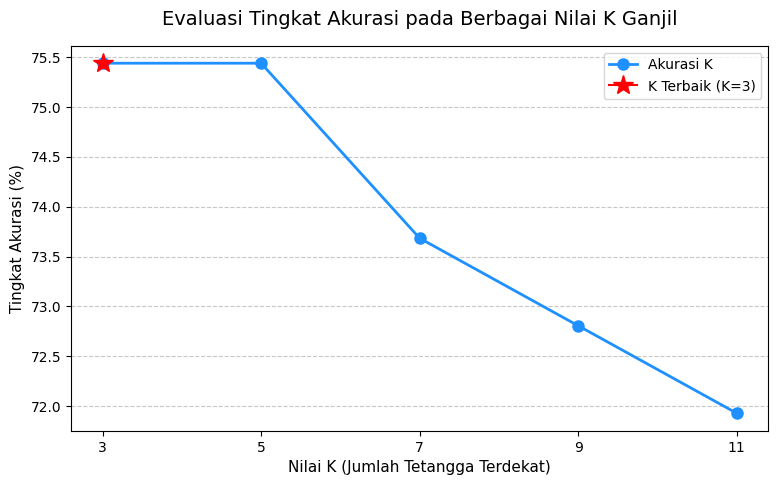


Sistem menentukan K optimal adalah K = 3 dengan akurasi dasar 75.44%
Proses training model KNN dan prediksi pada data uji berhasil diselesaikan!


In [11]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

print("\n--- 5 & 6. TRAINING KNN DAN KLASIFIKASI ---")

akurasi_terbaik = 0
k_terbaik = 3

# Menyiapkan list untuk menyimpan nilai K dan akurasinya (untuk keperluan grafik)
k_values = []
accuracies = []

# Loop untuk mencari nilai k ganjil terbaik dari k=3 hingga k=15
for k in range(3, 12, 2):
    knn_temp = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn_temp.fit(X_train, y_train)
    score = knn_temp.score(X_test, y_test)

    # Menyimpan data untuk digambar pada grafik (akurasi diubah ke persentase)
    k_values.append(k)
    accuracies.append(score * 100)

    if score > akurasi_terbaik:
        akurasi_terbaik = score
        k_terbaik = k

# =========================================================
# MENAMPILKAN GRAFIK PERBANDINGAN NILAI K
# =========================================================
plt.figure(figsize=(9, 5))

# Membuat garis grafik utama
plt.plot(k_values, accuracies, marker='o', linestyle='-', color='dodgerblue', linewidth=2, markersize=8, label='Akurasi K')

# Memberi tanda khusus (bintang merah) pada titik K yang paling optimal
plt.plot(k_terbaik, akurasi_terbaik * 100, marker='*', color='red', markersize=15, label=f'K Terbaik (K={k_terbaik})')

# Pengaturan label dan tampilan grafik
plt.title('Evaluasi Tingkat Akurasi pada Berbagai Nilai K Ganjil', fontsize=14, pad=15)
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)', fontsize=11)
plt.ylabel('Tingkat Akurasi (%)', fontsize=11)
plt.xticks(k_values) # Memastikan sumbu X hanya menampilkan angka K yang diuji
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()
# =========================================================

print(f"\nSistem menentukan K optimal adalah K = {k_terbaik} dengan akurasi dasar {akurasi_terbaik*100:.2f}%")

# Melatih ulang model final menggunakan K terbaik
knn_model = KNeighborsClassifier(n_neighbors=k_terbaik, weights='distance', metric='euclidean')
knn_model.fit(X_train, y_train)

# Proses Klasifikasi / Prediksi pada Data Uji
y_pred = knn_model.predict(X_test)
print("Proses training model KNN dan prediksi pada data uji berhasil diselesaikan!")


--- 7A. HASIL EVALUASI & CONFUSION MATRIX UNTUK SETIAP NILAI K ---

EVALUASI METRIK & CONFUSION MATRIX (K = 3)
Akurasi (Accuracy)  : 75.44%
Presisi (Precision) : 73.77%
Recall              : 73.88%
F1-Score            : 73.72%

[ Laporan Klasifikasi Detail ]
                 precision    recall  f1-score   support

         Normal       0.87      0.93      0.90        42
Risiko Stunting       0.56      0.58      0.57        31
       Stunting       0.78      0.71      0.74        41

       accuracy                           0.75       114
      macro avg       0.74      0.74      0.74       114
   weighted avg       0.75      0.75      0.75       114



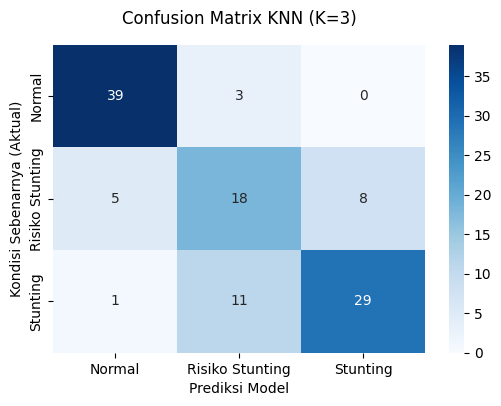


EVALUASI METRIK & CONFUSION MATRIX (K = 5)
Akurasi (Accuracy)  : 75.44%
Presisi (Precision) : 74.41%
Recall              : 74.39%
F1-Score            : 73.98%

[ Laporan Klasifikasi Detail ]
                 precision    recall  f1-score   support

         Normal       0.89      0.95      0.92        42
Risiko Stunting       0.56      0.65      0.60        31
       Stunting       0.79      0.63      0.70        41

       accuracy                           0.75       114
      macro avg       0.74      0.74      0.74       114
   weighted avg       0.76      0.75      0.75       114



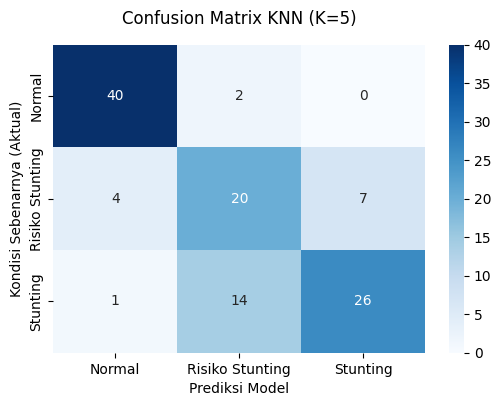


EVALUASI METRIK & CONFUSION MATRIX (K = 7)
Akurasi (Accuracy)  : 73.68%
Presisi (Precision) : 73.71%
Recall              : 73.05%
F1-Score            : 72.49%

[ Laporan Klasifikasi Detail ]
                 precision    recall  f1-score   support

         Normal       0.89      0.93      0.91        42
Risiko Stunting       0.53      0.68      0.59        31
       Stunting       0.80      0.59      0.68        41

       accuracy                           0.74       114
      macro avg       0.74      0.73      0.72       114
   weighted avg       0.76      0.74      0.74       114



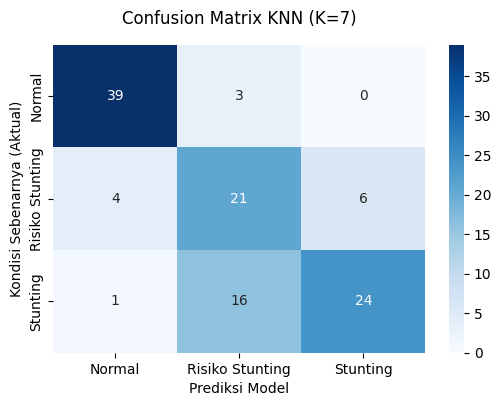


EVALUASI METRIK & CONFUSION MATRIX (K = 9)
Akurasi (Accuracy)  : 72.81%
Presisi (Precision) : 72.17%
Recall              : 71.73%
F1-Score            : 71.51%

[ Laporan Klasifikasi Detail ]
                 precision    recall  f1-score   support

         Normal       0.86      0.90      0.88        42
Risiko Stunting       0.51      0.61      0.56        31
       Stunting       0.79      0.63      0.70        41

       accuracy                           0.73       114
      macro avg       0.72      0.72      0.72       114
   weighted avg       0.74      0.73      0.73       114



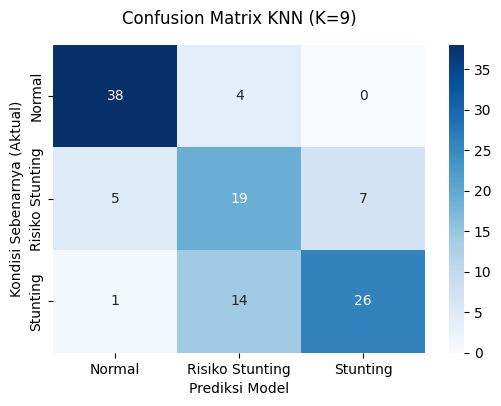


EVALUASI METRIK & CONFUSION MATRIX (K = 11)
Akurasi (Accuracy)  : 71.93%
Presisi (Precision) : 72.23%
Recall              : 71.20%
F1-Score            : 70.95%

[ Laporan Klasifikasi Detail ]
                 precision    recall  f1-score   support

         Normal       0.86      0.88      0.87        42
Risiko Stunting       0.50      0.65      0.56        31
       Stunting       0.81      0.61      0.69        41

       accuracy                           0.72       114
      macro avg       0.72      0.71      0.71       114
   weighted avg       0.74      0.72      0.72       114



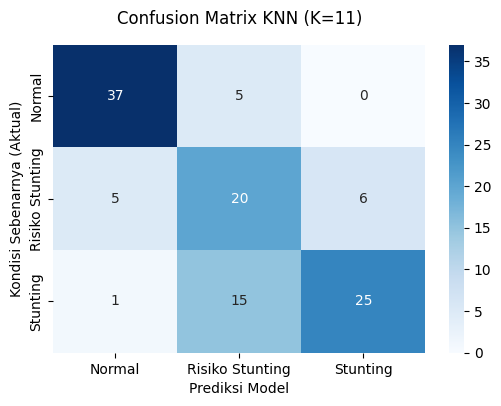

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns
import matplotlib.pyplot as plt

print("\n--- 7A. HASIL EVALUASI & CONFUSION MATRIX UNTUK SETIAP NILAI K ---")

# Menentukan rentang K ganjil yang diuji (3 hingga 12)
rentang_k = range(3, 12, 2)

for k in rentang_k:
    print("\n" + "="*60)
    print(f"EVALUASI METRIK & CONFUSION MATRIX (K = {k})")
    print("="*60)

    # Melatih ulang model sementara khusus untuk nilai K saat ini
    knn_eval = KNeighborsClassifier(n_neighbors=k, weights='distance', metric='euclidean')
    knn_eval.fit(X_train, y_train)

    # Melakukan Prediksi
    y_pred_eval = knn_eval.predict(X_test)

    # Menghitung Metrik Utama
    akurasi = accuracy_score(y_test, y_pred_eval)
    presisi = precision_score(y_test, y_pred_eval, average='macro', zero_division=0)
    recall = recall_score(y_test, y_pred_eval, average='macro', zero_division=0)
    f1 = f1_score(y_test, y_pred_eval, average='macro', zero_division=0)

    print(f"Akurasi (Accuracy)  : {akurasi * 100:.2f}%")
    print(f"Presisi (Precision) : {presisi * 100:.2f}%")
    print(f"Recall              : {recall * 100:.2f}%")
    print(f"F1-Score            : {f1 * 100:.2f}%")

    # Laporan Klasifikasi Rinci
    print("\n[ Laporan Klasifikasi Detail ]")
    print(classification_report(y_test, y_pred_eval, zero_division=0))

    # Visualisasi Grafik Confusion Matrix (Heatmap)
    cm = confusion_matrix(y_test, y_pred_eval)
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=knn_eval.classes_,
                yticklabels=knn_eval.classes_)
    plt.title(f'Confusion Matrix KNN (K={k})', pad=15)
    plt.xlabel('Prediksi Model')
    plt.ylabel('Kondisi Sebenarnya (Aktual)')

    # Menampilkan grafik langsung di bawah perhitungan metrik untuk K tersebut
    plt.show()


--- 7B. UJI KESTABILAN MODEL (5-FOLD CROSS VALIDATION) ---
Akurasi Tiap Fold (1-5) : [78.07 75.44 74.34 80.53 81.42]
Rata-rata Akurasi CV    : 77.96%



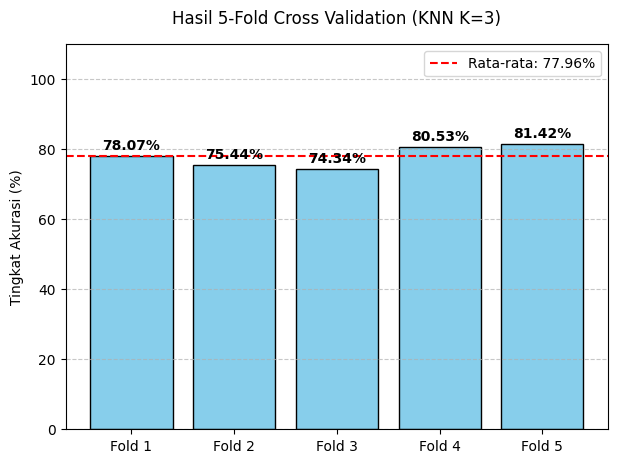

In [15]:
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt
import numpy as np

print("\n--- 7B. UJI KESTABILAN MODEL (5-FOLD CROSS VALIDATION) ---")

# Menghitung nilai Cross Validation
cv_scores = cross_val_score(knn_model, X, y, cv=5, scoring='accuracy')
cv_persen = cv_scores * 100
rata_rata_cv = cv_persen.mean()

print(f"Akurasi Tiap Fold (1-5) : {np.round(cv_persen, 2)}")
print(f"Rata-rata Akurasi CV    : {rata_rata_cv:.2f}%\n")

# Visualisasi Grafik Diagram Batang (Cross Validation)
fold_labels = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']

plt.figure(figsize=(7, 5))
bars = plt.bar(fold_labels, cv_persen, color='skyblue', edgecolor='black')

# Menambahkan garis putus-putus untuk menandai nilai rata-rata
plt.axhline(y=rata_rata_cv, color='red', linestyle='--', label=f'Rata-rata: {rata_rata_cv:.2f}%')

# Menambahkan angka persentase tepat di atas setiap batang grafik
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.2f}%',
             ha='center', va='bottom', fontsize=10, fontweight='bold')

# Pengaturan label dan tampilan grafik
plt.title(f'Hasil 5-Fold Cross Validation (KNN K={k_terbaik})', pad=15)
plt.ylabel('Tingkat Akurasi (%)')
plt.ylim(0, 110) # Memberi ruang agar angka tidak terpotong di atas grafik
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [19]:
from IPython.display import display

print("\n--- 8. OUTPUT SISTEM (HASIL KLASIFIKASI DATA UJI) ---")

# Mengambil kembali 5 baris pertama dari data X_test dan mengembalikan nilai yang belum dinormalisasi
indeks_uji = X_test.head(5).index
data_tampil = X_mentah.loc[indeks_uji].copy()

# Menyisipkan kolom Nama Balita dari data asli berdasarkan indeksnya (ditaruh di posisi paling kiri/awal)
data_tampil.insert(0, 'Nama Balita', df_bersih.loc[indeks_uji, 'Nama'])

# Menambahkan kolom Label Aktual dan Prediksi Sistem
data_tampil['Status Gizi Aktual'] = y_test.head(5).values
data_tampil['PREDIKSI SISTEM (KNN)'] = y_pred[:5]

# Mengubah kembali angka jenis kelamin menjadi teks untuk tampilan
data_tampil['Jenis_Kelamin_Encoded'] = data_tampil['Jenis_Kelamin_Encoded'].map({1: 'Laki-Laki', 0: 'Perempuan'})
data_tampil.rename(columns={'Jenis_Kelamin_Encoded': 'Jenis Kelamin'}, inplace=True)

print("Tabel Komparasi Kesimpulan Kelas Sistem KNN (5 Data Uji Pertama):")
display(data_tampil)


--- 8. OUTPUT SISTEM (HASIL KLASIFIKASI DATA UJI) ---
Tabel Komparasi Kesimpulan Kelas Sistem KNN (5 Data Uji Pertama):


,Nama Balita,Usia Saat Ukur,Berat,Tinggi,Jenis Kelamin,Status Gizi Aktual,PREDIKSI SISTEM (KNN)
540,ABDIEL BRIANDO DEJESUS,20,10.0,81.5,Laki-Laki,Normal,Normal
525,WAHID AHMAD FIRDAUS,5,7.2,63.7,Laki-Laki,Normal,Normal
234,GERAL AMARAL,7,7.8,66.3,Laki-Laki,Normal,Normal
526,MORGALIFA C. MELLO,5,6.5,63.0,Perempuan,Normal,Normal
490,SALITA SANAM,8,8.0,68.1,Perempuan,Normal,Normal
